# Cross-section of the wind component parallel to the section

A vertical cross-section shows how a quantity changes with height along a line over the Earth's surface. In this tutorial we plot the wind component along the line (positive in the direction of travel) for superstorm Sandy, along a line from (30.30°N, 79.83°W) to (36.95°N, 63.92°W), together with a map of the line.

This feature is **experimental**. For a more detailed version of this example, see [the high-level notebook](../high/cross_section_wind_parallel.ipynb).

## Imports

First we import the tools we need.

In [1]:
import sys
from datetime import datetime

import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
from earthkit.geo.polyline import sample_polyline

sys.path.insert(0, "..")  # xsection.py is in docs/experimental
from xsection import cross_section, wind_components

## Get the data

We load a small sample file with forecast data of superstorm Sandy. We pick the wind components (`u` and `v`) on all pressure levels, and the geopotential (`z`) at 500 hPa for the map.

In [2]:
ds = ekd.from_source("sample", "sandy_pl_025.grib").to_fieldlist()

fl = ds.sel({"parameter.variable": ["u", "v"]})
z500 = ds.sel({"parameter.variable": "z", "vertical.level": 500})

sandy_pl_025.grib:   0%|          | 0.00/516k [00:00<?, ?B/s]

## Define the line

We choose 200 evenly spaced points along a straight line in latitude and longitude, from (30.30°N, 79.83°W) to (36.95°N, 63.92°W).

In [3]:
lats, lons = sample_polyline([30.30, 36.95], [-79.83, -63.92], n=200, method="linear")

## Compute the cross-section

Now we compute the values of the wind components at the points of the line. Log messages may appear while this runs; you can ignore them.

In [4]:
xs = cross_section(fl, lats, lons)

Error setting gridSpec={"type": "unstructured_ll", "uid": "2d0e938b6cc70f9291d1b380c9e1ed10"}
ECCODES ERROR   :  grib_set_from_grid_spec: 'unstructured_grid' specified but input is GRIB edition 1.
ECCODES ERROR   :  GribFromSpec::set: Invalid argument


Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

## Compute the parallel wind component

We compute the wind component along the line (positive in the direction of travel) from `u` and `v`. It is added to the data as `wp`.

In [5]:
xs = wind_components(xs, method="linear")
xs

<xarray.Dataset> Size: 75kB
Dimensions:                  (level: 11, distance: 200)
Coordinates:
  * level                    (level) int64 88B 100 150 200 250 ... 850 925 1000
  * distance                 (distance) float64 2kB 0.0 8.527 ... 1.648e+03
    latitude                 (distance) float64 2kB 30.3 30.33 ... 36.92 36.95
    longitude                (distance) float64 2kB -79.83 -79.75 ... -63.92
    forecast_reference_time  datetime64[ns] 8B 2012-10-29
    step                     timedelta64[ns] 8B 00:00:00
    valid_time               datetime64[ns] 8B ...
Data variables:
    u                        (level, distance) float64 18kB 13.23 ... -13.85
    v                        (level, distance) float64 18kB 17.12 ... 4.343
    wn                       (level, distance) float64 18kB 9.642 ... 10.27
    wp                       (level, distance) float64 18kB 19.36 ... -10.26
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Plot the map and the cross-section

The geopotential is in m²/s², so we first convert it to geopotential height in dam, which is what we draw on the map. Then we plot the map with the line in red above, and below it the wind component on the cross-section, with pressure on a logarithmic axis.

In [6]:
# convert the geopotential from m2/s2 to geopotential height in dam
z500_dam = z500.to_xarray()["z"] / 98.0665
z500_dam.attrs = {"units": "dam", "long_name": "Geopotential height"}

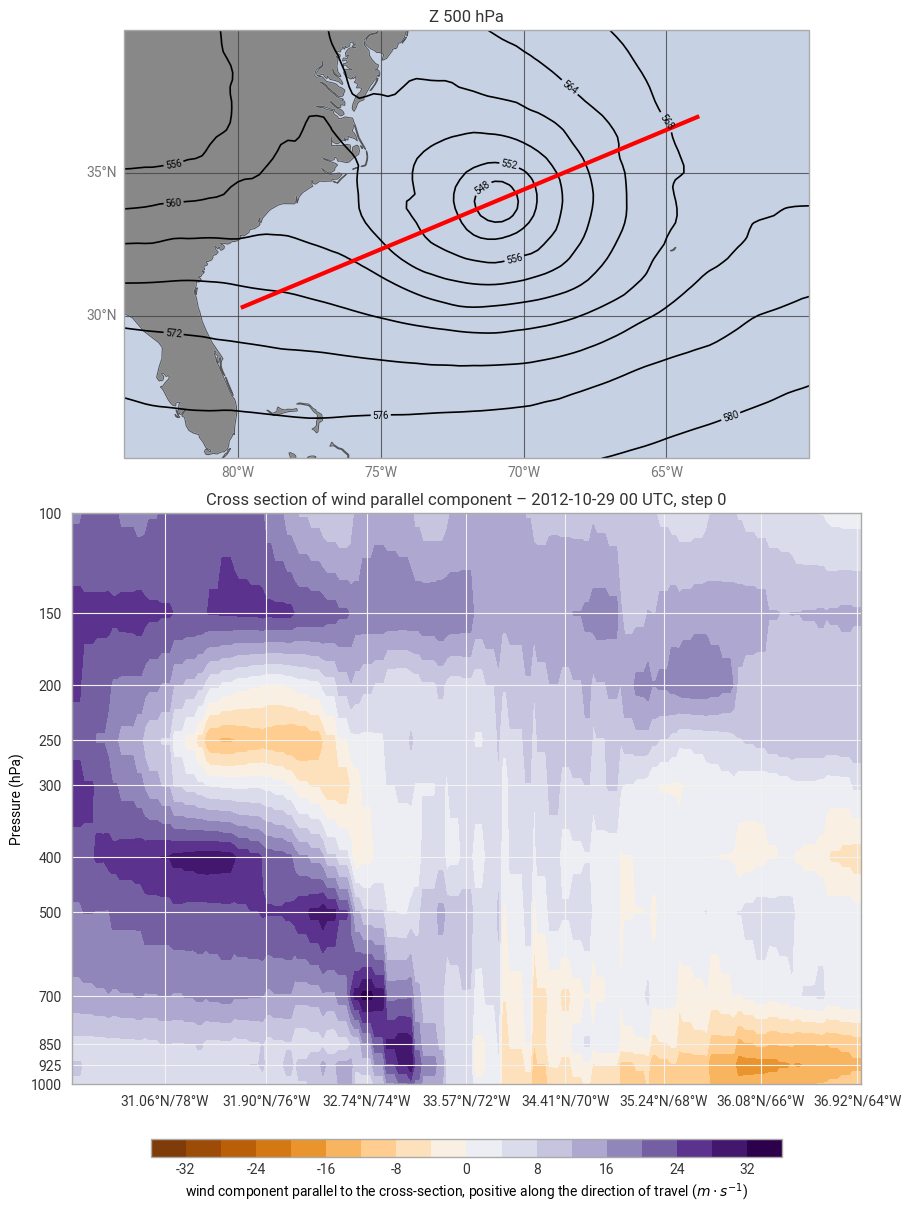

In [7]:
import cartopy.crs as ccrs  # plain latitude-longitude projection for the map

base_date = datetime(2012, 10, 29, 0)
wp_levels = list(range(-36, 37, 4))

lats, lons, distance = xs["latitude"].values, xs["longitude"].values, xs["distance"].values

fig = ekp.Figure(rows=2, columns=1, figsize=(9, 12), height_ratios=[3, 4])

# --- map: z500 and the cross-section line ---
m = fig.add_map(domain=[-84, -60, 25, 40], crs=ccrs.PlateCarree())  # [west, east, south, north]
m.land(color="#888888")
m.ocean(color="#c6d1e4")
m.coastlines()
m.gridlines(xstep=5, ystep=5, color="#434343", linewidth=0.8)
m.contour(
    z500_dam,
    style=ekp.styles.Contour(levels=list(range(400, 640, 4)), colors="black", labels=True, linewidths=1.2),
    resample=False,
)
m.line(x=[lons[0], lons[-1]], y=[lats[0], lats[-1]], color="red", linewidth=3)
m.title("Z 500 hPa")

# --- cross-section: wind parallel component ---
c = fig.add_subplot()
c.contourf(
    xs["wp"],
    x="distance",
    y="level",
    style=ekp.styles.Style(levels=wp_levels, colors="PuOr"),
    resample=False,
)
fig.legend(subplots=[c])

# 8 ticks where the line crosses the longitudes 78W ... 64W (lons increase along the line)
tick_lons = np.arange(-78, -63, 2)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{lat:.2f}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]

ax = c.ax
ax.set_yscale("log")
ax.set_ylim(1000, 100)  # 1000 hPa at the bottom, 100 hPa at the top
pressure_ticks = [1000, 925, 850, 700, 500, 400, 300, 250, 200, 150, 100]
ax.set_yticks(pressure_ticks)
ax.set_yticklabels([str(p) for p in pressure_ticks])
ax.minorticks_off()
ax.set_xlim(distance[0], distance[-1])
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.set_ylabel("Pressure (hPa)")
ax.set_title(f"Cross section of wind parallel component – {base_date:%Y-%m-%d %H} UTC, step 0")

fig.show()